# Лабораторная работа № 1. Нейронные сети
## Обучение полносвязных нейронных сетей: классификаторы и регрессор
**Вариант 5 :**
| Задача | Набор данных | Целевой признак |
|---|---|---|
| Бинарная классификация | Diabetes Health Indicators | `Diabetes_012` → 0 — нет диабета, 1 — преддиабет/диабет (значения 1 и 2 объединены) |
| Многоклассовая классификация | Body Performance | `class` (A, B, C, D) |
| Регрессия | White wine Quality | `quality` |

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
import seaborn as sns
import keras
import math
from keras import layers, regularizers, callbacks
from keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, recall_score, precision_score,
    f1_score, balanced_accuracy_score, accuracy_score, roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, classification_report)

SEED = 42
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

# Набор исследуемых архитектур
CFGS = [
 dict(name="MLP-1", hidden=[32],         act="relu", opt="adam",    lr=1e-3, batch=32, dropout=0.0, l2=0.0),   # компактная
 dict(name="MLP-2", hidden=[64, 32],     act="relu", opt="adam",    lr=1e-3, batch=32, dropout=0.2, l2=0.0),   # средняя + Dropout
 dict(name="MLP-3", hidden=[128, 64, 32],act="relu", opt="adam",    lr=1e-3, batch=32, dropout=0.3, l2=1e-4),  # глубокая + Dropout + L2
 dict(name="MLP-4", hidden=[64, 32],     act="tanh", opt="rmsprop", lr=1e-3, batch=32, dropout=0.0, l2=0.0),   # tanh + RMSprop
 dict(name="MLP-5", hidden=[64, 32],     act="relu", opt="sgd",     lr=1e-2, batch=32, dropout=0.0, l2=0.0),   # SGD + momentum 0.9
]

random.seed(SEED);
np.random.seed(SEED);
tf.keras.utils.set_random_seed(SEED)


In [37]:
def split_dataset(X, y, stratify=True):

    # Правильно разбивает датасет на train/val/test в пропорции 70/15/15

    s = y if stratify else None
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, 
        test_size=1 - TRAIN_FRAC, 
        random_state=SEED, 
        stratify=s
    )
    
    s = y_tmp if stratify else None
    val_ratio_of_tmp = TEST_FRAC / (VAL_FRAC + TEST_FRAC)
    
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, 
        test_size=val_ratio_of_tmp, 
        random_state=SEED, 
        stratify=s
    )

    return X_tr, X_va, X_te, y_tr, y_va, y_te

def preprocess_datasets(X_tr, X_va, X_te):

    # Выполняет импутацию (медиана/мода), One-Hot кодирование и StandardScaler.
    # Все параметры (медианы, средние, категории) обучаются ТОЛЬКО на train выборке.
    
    X_tr = X_tr.copy()
    X_va = X_va.copy()
    X_te = X_te.copy()

    num_cols = X_tr.select_dtypes(include="number").columns.tolist()
    cat_cols = X_tr.select_dtypes(include=["object", "category", "string"]).columns.tolist()
    
    all_processed = num_cols + cat_cols
    extra_cols = [c for c in X_tr.columns if c not in all_processed]
    cat_cols.extend(extra_cols)


    num_pipeline = Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=True)), 
        ("sc", StandardScaler())
    ])

    cat_pipeline = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent", add_indicator=True)),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ])
    
    X_tr_processed = preprocessor.fit_transform(X_tr).astype("float32")
    X_va_processed = preprocessor.transform(X_va).astype("float32")
    X_te_processed = preprocessor.transform(X_te).astype("float32")
    
    print(f"Предобработка завершена:")
    print(f"  Числовых признаков: {len(num_cols)}")
    print(f"  Категориальных признаков: {len(cat_cols)}")
    print(f"  Итоговая размерность матрицы (кол-во колонок): {X_tr_processed.shape[1]}")
    
    return X_tr_processed, X_va_processed, X_te_processed, preprocessor


## 1. Бинарная классификация: Diabetes Health Indicators
Положительный класс (1) = преддиабет или диабет (исходные значения 1 и 2 объединены), отрицательный (0) = нет диабета.

In [38]:
diabetes = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")
print("Размер:", diabetes.shape, "| пропусков:", int(diabetes.isna().sum().sum()), "| полных дубликатов:", int(diabetes.duplicated().sum()))
print("\nИсходное распределение Diabetes_012:\n", diabetes["Diabetes_012"].value_counts().sort_index())

diabetes["target"] = (diabetes["Diabetes_012"] > 0).astype(int)    
vc = diabetes["target"].value_counts().sort_index(); 
print("\nБинарная метка:\n", pd.DataFrame({"n": vc, "доля": (vc/len(diabetes)).round(4)}))

diabetes = diabetes.drop_duplicates()
X = diabetes.drop(columns=["Diabetes_012", "target"])
y = diabetes["target"].values
Xtr_df, Xva_df, Xte_df, ytr_b, yva_b, yte_b = split_dataset(X, y, stratify=True)

Xtr_b, Xva_b, Xte_b, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)
print("Доля положительного класса train/val/test:", ytr_b.mean().round(4), yva_b.mean().round(4), yte_b.mean().round(4))

cw = {0: len(ytr_b)/(2*(ytr_b==0).sum()), 1: len(ytr_b)/(2*(ytr_b==1).sum())}   # class_weight только для train
print("class_weight:", {k: round(v, 3) for k, v in cw.items()})

Размер: (253680, 22) | пропусков: 0 | полных дубликатов: 23899

Исходное распределение Diabetes_012:
 Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

Бинарная метка:
              n    доля
target                
0       213703  0.8424
1        39977  0.1576
Предобработка завершена:
  Числовых признаков: 21
  Категориальных признаков: 0
  Итоговая размерность матрицы (кол-во колонок): 21
Доля положительного класса train/val/test: 0.1729 0.1729 0.1729
class_weight: {0: np.float64(0.605), 1: np.float64(2.892)}


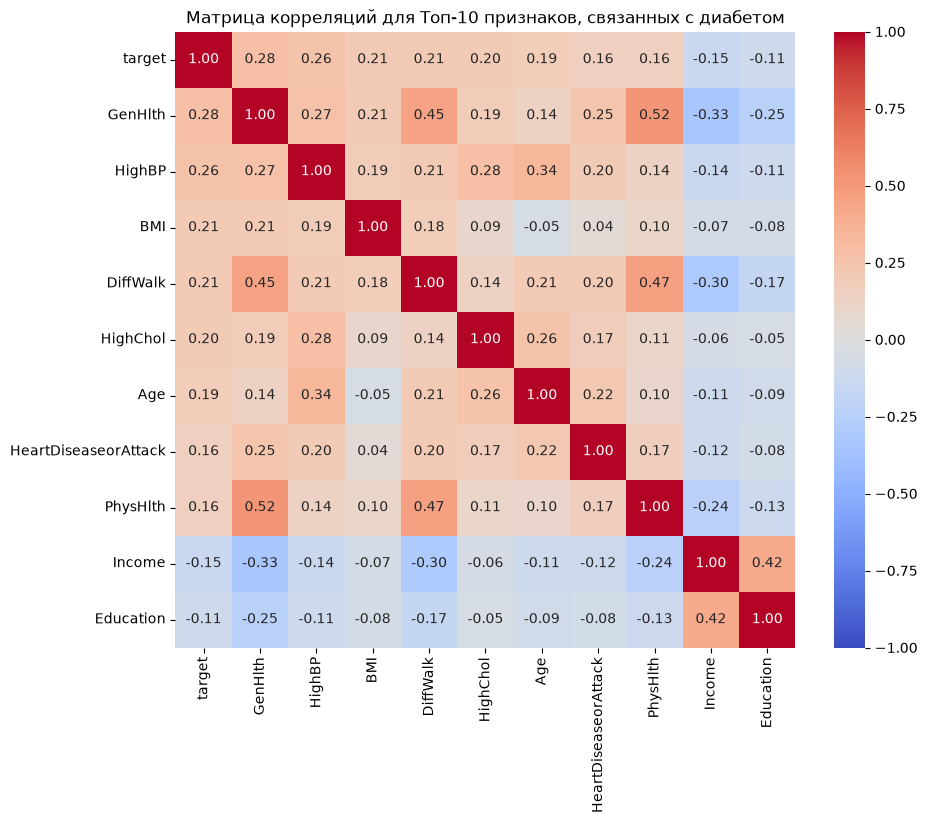

In [39]:
train_df = Xtr_df.copy()
train_df['target'] = ytr_b
full_corr = train_df.corr(method='pearson')

top_features = full_corr['target'].abs().sort_values(ascending=False).head(11).index

plt.figure(figsize=(10, 8))
sns.heatmap(full_corr.loc[top_features, top_features], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций для Топ-10 признаков, связанных с диабетом")
plt.show()

In [40]:
def best_threshold(y, p):
    
    # Находит порог (от 0.05 до 0.95), максимизирующий Balanced Accuracy.
    
    # Создаем сетку порогов
    ths = np.arange(0.05, 0.951, 0.01)
    
    # Превращаем одномерный массив вероятностей p в матрицу предсказаний размера
    # Каждая строка соответствует своему порогу
    preds = (p >= ths[:, None]).astype(int)
    
    # Считаем сбалансированную точность для каждого порога
    scores = [balanced_accuracy_score(y, pred) for pred in preds]
    
    # Находим индекс максимального скора и возвращаем соответствующий порог
    best_idx = np.argmax(scores)
    return float(ths[best_idx])

def bin_metrics(y, p, thr):
    
    # Вычисляет комплекс основных метрик бинарной классификации для заданного порога отсечения вероятностей.
    
    # Бинаризуем вероятности по выбранному порогу
    pred = (p >= thr).astype(int)
    
    metrics = {
        "Recall": recall_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "BalancedAcc": balanced_accuracy_score(y, pred),
        "ROC_AUC": roc_auc_score(y, p),
        "F1": f1_score(y, pred)
    }
    
    return metrics

def plot_histories(hist_dict, title):
    # Рисует кривые обучения (train/val loss) для каждой модели из hist_dict.

    names = list(hist_dict)
    n = len(names)
    ncols = min(3, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows), squeeze=False)

    for ax in axes.ravel():          # спрятать лишние оси
        ax.set_visible(False)

    for ax, name in zip(axes.ravel(), names):
        h = hist_dict[name]
        ep = range(1, len(h["loss"]) + 1)
        ax.plot(ep, h["loss"], label="train")
        ax.plot(ep, h["val_loss"], label="validation")
        ax.set_title(name)
        ax.set_xlabel("Эпоха"); ax.set_ylabel("Loss")
        ax.legend(); ax.grid(alpha=0.3)
        ax.set_visible(True)

    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

def build_mlp(cfg, input_dim, task, n_classes=None):
    reg = regularizers.l2(cfg["l2"]) if cfg.get("l2", 0) > 0 else None
    
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in cfg["hidden"]:
        model.add(layers.Dense(units, activation=cfg["act"], kernel_regularizer=reg))
        if cfg.get("dropout", 0) > 0:
            model.add(layers.Dropout(cfg["dropout"]))
            
    if task == "regression":
        model.add(layers.Dense(1))
        loss = "mse"
    elif task == "binary":
        model.add(layers.Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    elif task == "multiclass":
        if n_classes is None:
            raise ValueError("Параметр 'n_classes' обязателен для мультиклассовой классификации (task='multiclass').")
        model.add(layers.Dense(n_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"
    else:
        raise ValueError(f"Неизвестный тип задачи: '{task}'. Допустимые: 'regression', 'binary', 'multiclass'.")
        
    lr = cfg["lr"]
    opt_name = cfg["opt"].lower()
    
    if opt_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate=lr)
    elif opt_name == "rmsprop":
        optimizer = keras.optimizers.RMSprop(learning_rate=lr)
    elif opt_name == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    else:
        raise ValueError(f"Неизвестный оптимизатор: '{opt_name}'. Допустимые: 'adam', 'rmsprop', 'sgd'.")
        
    model.compile(optimizer=optimizer, loss=loss)
    
    return model

In [41]:
bin_rows = []
bin_hist, bin_models, bin_probs = {}, {}, {}

for cfg0 in CFGS:
    cfg = {**cfg0, "batch": 512}

    model = build_mlp(
        cfg=cfg, 
        input_dim=Xtr_b.shape[1], 
        task="binary"
    )

    es = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    h = model.fit(
        Xtr_b, ytr_b, 
        validation_data=(Xva_b, yva_b),
        epochs=60, 
        batch_size=cfg["batch"],
        callbacks=[es], 
        class_weight=cw, 
        verbose=0
    )

    pva = model.predict(Xva_b, verbose=0).ravel()
    pte = model.predict(Xte_b, verbose=0).ravel()
    thr = best_threshold(yva_b, pva)

    bin_hist[cfg["name"]] = h.history
    bin_models[cfg["name"]] = model
    bin_probs[cfg["name"]] = (pva, pte, thr)
    
    bin_rows.append(dict(
        Модель=cfg["name"], 
        Порог=round(thr, 2),
        Эпох=int(np.argmin(h.history["val_loss"])) + 1,
        **{"Val ROC_AUC": roc_auc_score(yva_b, pva)},
        **bin_metrics(yte_b, pte, thr)
    ))

    print(classification_report(yte_b, (pte >= thr).astype(int), digits=4))
    keras.backend.clear_session()


bin_df = pd.DataFrame(bin_rows)
print("\n" + bin_df.round(4).to_string(index=False))

              precision    recall  f1-score   support

           0     0.9323    0.7120    0.8074     28509
           1     0.3533    0.7528    0.4809      5959

    accuracy                         0.7190     34468
   macro avg     0.6428    0.7324    0.6442     34468
weighted avg     0.8322    0.7190    0.7510     34468

              precision    recall  f1-score   support

           0     0.9368    0.6875    0.7930     28509
           1     0.3423    0.7780    0.4754      5959

    accuracy                         0.7032     34468
   macro avg     0.6395    0.7328    0.6342     34468
weighted avg     0.8340    0.7032    0.7381     34468

              precision    recall  f1-score   support

           0     0.9358    0.6942    0.7971     28509
           1     0.3455    0.7723    0.4774      5959

    accuracy                         0.7077     34468
   macro avg     0.6407    0.7333    0.6373     34468
weighted avg     0.8338    0.7077    0.7419     34468

              preci

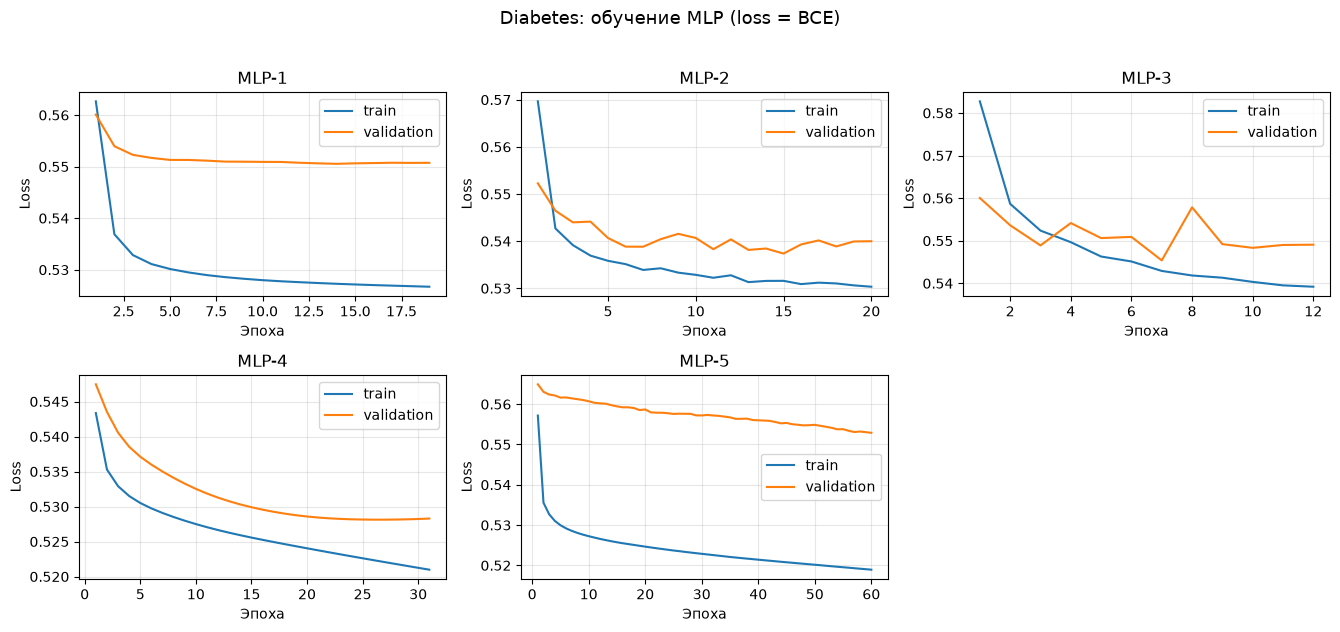

In [42]:
plot_histories(bin_hist, "Diabetes: обучение MLP (loss = BCE)")

Лучшая модель по Val ROC-AUC: MLP-2, порог = 0.50


Text(0.5, 1.0, 'ROC-кривые (test)')

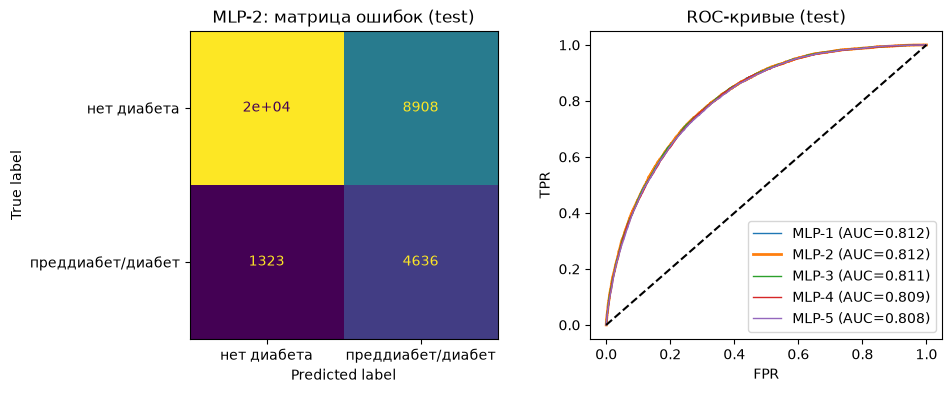

In [43]:
nn = bin_df[bin_df["Модель"].str.startswith("MLP")]
bname = nn.loc[nn["Val ROC_AUC"].idxmax(), "Модель"]
pva, pte, thr = bin_probs[bname]
print(f"Лучшая модель по Val ROC-AUC: {bname}, порог = {thr:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(yte_b, (pte >= thr).astype(int)), display_labels=["нет диабета", "преддиабет/диабет"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title(f"{bname}: матрица ошибок (test)")

for n_, (_, pt_, _) in bin_probs.items():
    f, t, _ = roc_curve(yte_b, pt_); ax[1].plot(f, t, label=f"{n_} (AUC={roc_auc_score(yte_b, pt_):.3f})", lw=2 if n_ == bname else 1)
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(); ax[1].set_title("ROC-кривые (test)")


## 2. Многоклассовая классификация: Body Performance
Классы A, B, C, D кодируются числами; признак `gender` — категориальный (One-Hot).

In [44]:
body = pd.read_csv("bodyPerformance.csv")
print("Размер:", body.shape, "| пропусков:", int(body.isna().sum().sum()), "| полных дубликатов:", int(body.duplicated().sum()))
print(body.dtypes.to_string())

vc = body["class"].value_counts().sort_index(); print("\nКлассы:\n", pd.DataFrame({"n": vc, "доля": (vc/len(body)).round(4)}))

le = LabelEncoder(); 
y_m = le.fit_transform(body["class"]); CLASSES = list(le.classes_); K = len(CLASSES)
X = body.drop(columns=["class"])      # идентификаторов и признаков с утечкой нет
Xtr_df, Xva_df, Xte_df, ytr_m, yva_m, yte_m = split_dataset(X, y_m, stratify=True)
Xtr_m, Xva_m, Xte_m, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)

Размер: (13393, 12) | пропусков: 0 | полных дубликатов: 1
age                        float64
gender                         str
height_cm                  float64
weight_kg                  float64
body fat_%                 float64
diastolic                  float64
systolic                   float64
gripForce                  float64
sit and bend forward_cm    float64
sit-ups counts             float64
broad jump_cm              float64
class                          str

Классы:
           n    доля
class              
A      3348  0.2500
B      3347  0.2499
C      3349  0.2501
D      3349  0.2501
Предобработка завершена:
  Числовых признаков: 10
  Категориальных признаков: 1
  Итоговая размерность матрицы (кол-во колонок): 12


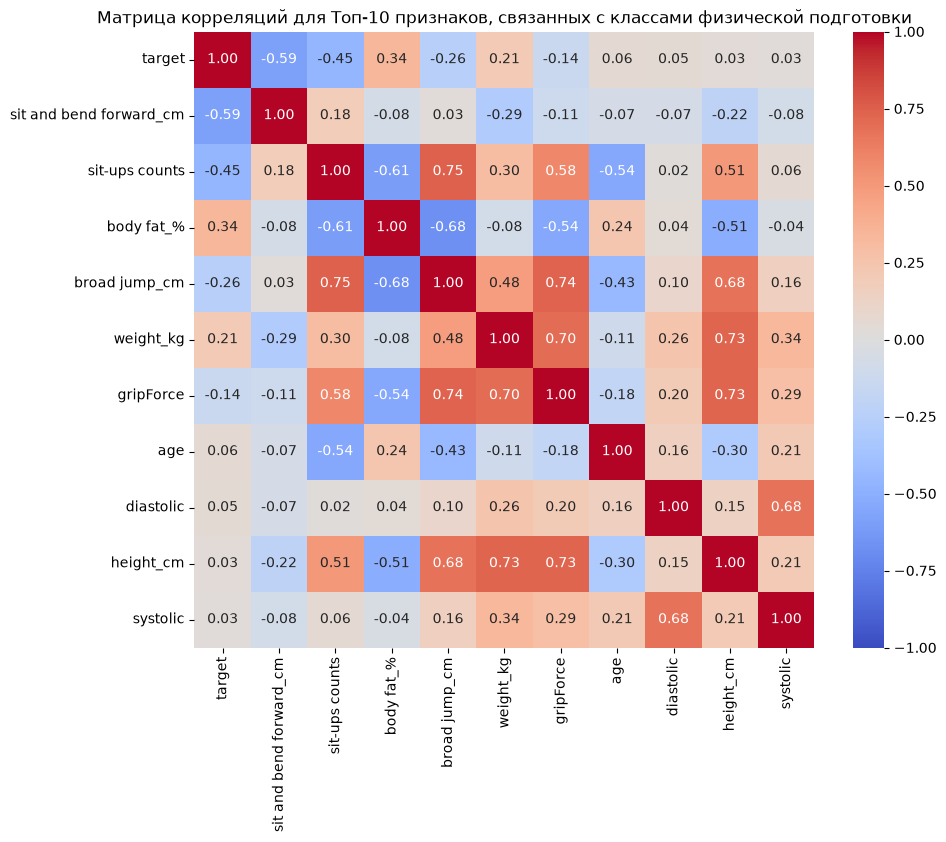

In [45]:
train_df = Xtr_df.copy()
train_df['target'] = ytr_m
full_corr = train_df.corr(method='pearson', numeric_only=True)

top_features = full_corr['target'].abs().sort_values(ascending=False).head(11).index

plt.figure(figsize=(10, 8))
sns.heatmap(full_corr.loc[top_features, top_features], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций для Топ-10 признаков, связанных с классами физической подготовки")
plt.show()

In [46]:
def multi_eval(y, proba, k):
    pred = proba.argmax(1)
    rep = classification_report(y, pred, target_names=CLASSES, output_dict=True, zero_division=0)
    Y = label_binarize(y, classes=list(range(k)))
    aucs = [roc_auc_score(Y[:, i], proba[:, i]) for i in range(k)]          # One-vs-Rest
    return dict(rep=rep, bal=balanced_accuracy_score(y, pred), aucs=aucs, macro_auc=float(np.mean(aucs)), acc=accuracy_score(y, pred), pred=pred)

mc = {}
mc_val = {}
mc_hist = {}
mc_proba = {}
mc_models = {}

for cfg in CFGS:
    model = build_mlp(cfg, Xtr_m.shape[1], "multiclass", n_classes=K)
    
    es = keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=15,
        restore_best_weights=True, 
        verbose=0
    )
    
    h = model.fit(
        Xtr_m, ytr_m, 
        validation_data=(Xva_m, yva_m),
        epochs=200, 
        batch_size=64, 
        callbacks=[es], 
        verbose=0
    )

    # Генерация предсказаний БЕЗ дублирования вызовов
    preds_va = model.predict(Xva_m, verbose=0)
    preds_te = model.predict(Xte_m, verbose=0)
    
    mc_hist[cfg["name"]] = h.history
    mc_models[cfg["name"]] = model
    mc_proba[cfg["name"]] = preds_te
    
    mc_val[cfg["name"]] = multi_eval(yva_m, preds_va, K)
    mc[cfg["name"]] = multi_eval(yte_m, preds_te, K)
    
    print("[b]", cfg["name"], "готово")
    print(classification_report(yte_m, mc[cfg["name"]]["pred"], target_names=CLASSES, digits=4))
    keras.backend.clear_session()

summB = pd.DataFrame([dict(
    Модель=n,
    **{
        "Val BalAcc": mc_val[n]["bal"],
        "Test Accuracy": r["acc"], 
        "Test BalAcc": r["bal"],
        "Test macro ROC-AUC (OvR)": r["macro_auc"],
        "Test macro F1": r["rep"]["macro avg"]["f1-score"]
    }) for n, r in mc.items()
])

print(summB.round(4).to_string(index=False))


[b] MLP-1 готово
              precision    recall  f1-score   support

           A     0.7034    0.9024    0.7906       502
           B     0.6538    0.6056    0.6287       502
           C     0.7550    0.6740    0.7122       503
           D     0.9246    0.8307    0.8751       502

    accuracy                         0.7531      2009
   macro avg     0.7592    0.7532    0.7517      2009
weighted avg     0.7592    0.7531    0.7516      2009

[b] MLP-2 готово
              precision    recall  f1-score   support

           A     0.6922    0.9363    0.7959       502
           B     0.6765    0.5956    0.6335       502
           C     0.7756    0.6938    0.7324       503
           D     0.9475    0.8267    0.8830       502

    accuracy                         0.7631      2009
   macro avg     0.7729    0.7631    0.7612      2009
weighted avg     0.7729    0.7631    0.7612      2009

[b] MLP-3 готово
              precision    recall  f1-score   support

           A     0.7062 

Модель       Метрика      A      B      C      D  Macro avg  Weighted avg
 MLP-1     precision 0.7034 0.6538 0.7550 0.9246     0.7592        0.7592
 MLP-1        recall 0.9024 0.6056 0.6740 0.8307     0.7532        0.7531
 MLP-1      f1-score 0.7906 0.6287 0.7122 0.8751     0.7517        0.7516
 MLP-1 ROC-AUC (OvR) 0.9519 0.8788 0.9018 0.9602     0.9232           NaN
 MLP-2     precision 0.6922 0.6765 0.7756 0.9475     0.7729        0.7729
 MLP-2        recall 0.9363 0.5956 0.6938 0.8267     0.7631        0.7631
 MLP-2      f1-score 0.7959 0.6335 0.7324 0.8830     0.7612        0.7612
 MLP-2 ROC-AUC (OvR) 0.9548 0.8866 0.9070 0.9655     0.9285           NaN
 MLP-3     precision 0.7062 0.6630 0.7612 0.9168     0.7618        0.7618
 MLP-3        recall 0.9143 0.5996 0.6779 0.8347     0.7566        0.7566
 MLP-3      f1-score 0.7969 0.6297 0.7171 0.8738     0.7544        0.7544
 MLP-3 ROC-AUC (OvR) 0.9520 0.8855 0.9076 0.9645     0.9274           NaN
 MLP-4     precision 0.7000 0.6535 0.7

C:\Users\Admin\AppData\Local\Temp\ipykernel_24748\1622875732.py:21: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tabB.rename(columns={c: CLASSES[c] for c in range(K)}, inplace=True)


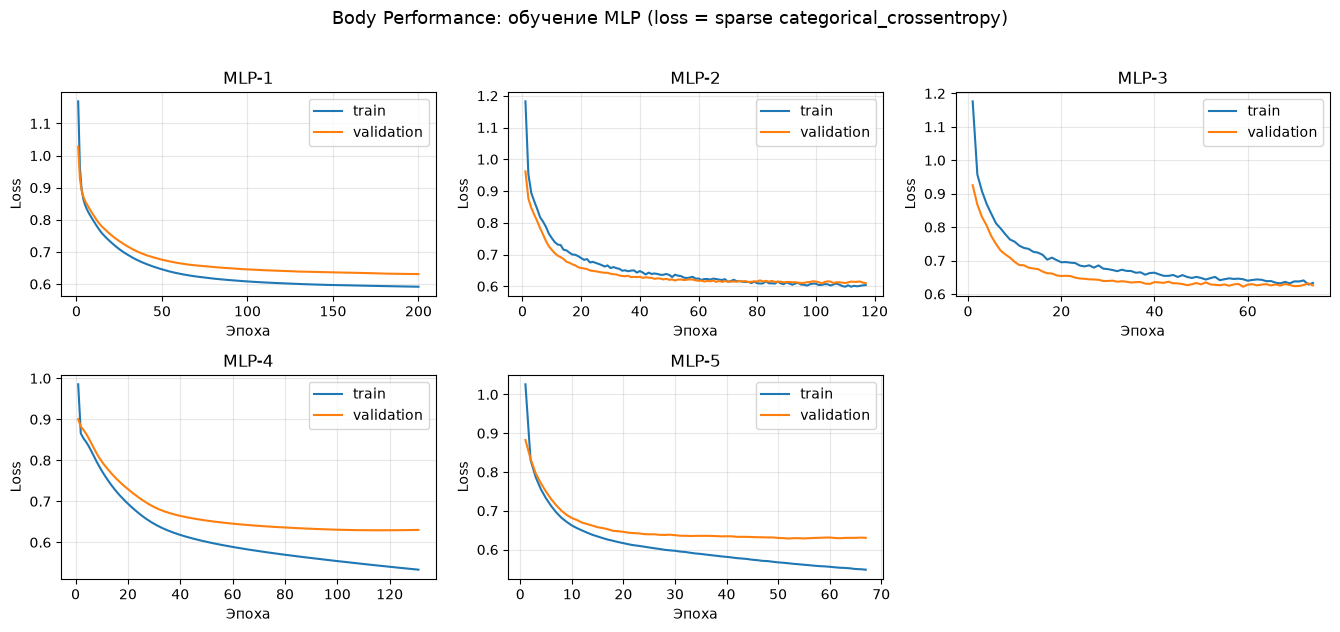

In [47]:
rows = []
for n, r in mc.items():
    for met in ["precision", "recall", "f1-score"]:
        rows.append({
            "Модель": n,
            "Метрика": met,
            **{c: r["rep"][CLASSES[c]][met] for c in range(K)},
            "Macro avg": r["rep"]["macro avg"][met],
            "Weighted avg": r["rep"]["weighted avg"][met]
        })

    rows.append({
        "Модель": n,
        "Метрика": "ROC-AUC (OvR)",
        **{c: a for c, a in zip(range(K), r["aucs"])},
        "Macro avg": r["macro_auc"],
        "Weighted avg": np.nan
    })

tabB = pd.DataFrame(rows)
tabB.rename(columns={c: CLASSES[c] for c in range(K)}, inplace=True)
print(tabB.round(4).to_string(index=False))

plot_histories(
    mc_hist,
    "Body Performance: обучение MLP (loss = sparse categorical_crossentropy)"
)

Лучшая модель по Val Balanced Accuracy: MLP-3


Text(0.5, 1.0, 'MLP-3: ROC One-vs-Rest (test), macro AUC=0.927')

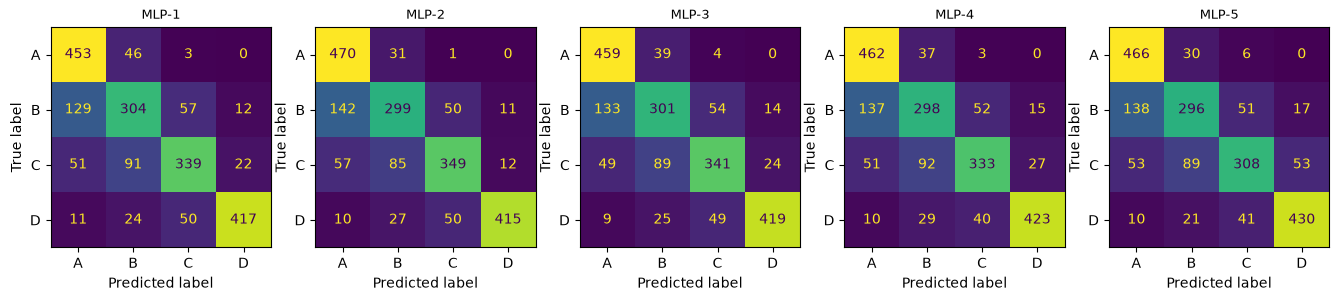

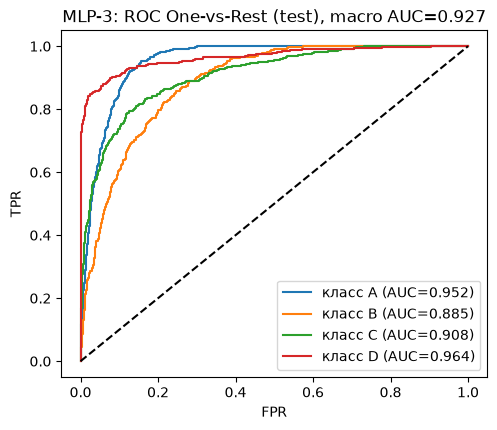

In [48]:
# Матрицы ошибок всех моделей
names = list(mc.keys()); fig, axs = plt.subplots(1, len(names), figsize=(3.3*len(names), 3.3))
for ax, n in zip(axs, names):
    ConfusionMatrixDisplay(confusion_matrix(yte_m, mc[n]["pred"]), display_labels=CLASSES).plot(ax=ax, colorbar=False); ax.set_title(n, fontsize=9)

# Лучшая модель по Val Balanced Accuracy и её ROC-кривые OvR
nn_names = [n for n in mc if n.startswith("MLP")]; mname = max(nn_names, key=lambda n: mc_val[n]["bal"])
print("Лучшая модель по Val Balanced Accuracy:", mname)
Y = label_binarize(yte_m, classes=list(range(K))); plt.figure(figsize=(5.5, 4.5))
for i, c in enumerate(CLASSES):
    f, t, _ = roc_curve(Y[:, i], mc_proba[mname][:, i]); plt.plot(f, t, label=f"класс {c} (AUC={mc[mname]['aucs'][i]:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title(f"{mname}: ROC One-vs-Rest (test), macro AUC={mc[mname]['macro_auc']:.3f}")


## 3. Регрессия: Wine Quality (white), целевой признак `quality`

In [49]:
wine = pd.read_csv("winequality-white.csv", sep=";")
print("Размер:", wine.shape); print("\nТипы столбцов:\n", wine.dtypes.value_counts())
print("\nПропуски:", int(wine.isna().sum().sum()), "| Полных дубликатов строк:", int(wine.duplicated().sum()))
print("\nОписательная статистика целевого признака:\n", wine["quality"].describe().round(3))
print("\nРаспределение quality:\n", wine["quality"].value_counts().sort_index())


Размер: (4898, 12)

Типы столбцов:
 float64    11
int64       1
Name: count, dtype: int64

Пропуски: 0 | Полных дубликатов строк: 937

Описательная статистика целевого признака:
 count    4898.000
mean        5.878
std         0.886
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         9.000
Name: quality, dtype: float64

Распределение quality:
 quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


После удаления дубликатов: (3961, 12)
Предобработка завершена:
  Числовых признаков: 11
  Категориальных признаков: 0
  Итоговая размерность матрицы (кол-во колонок): 11


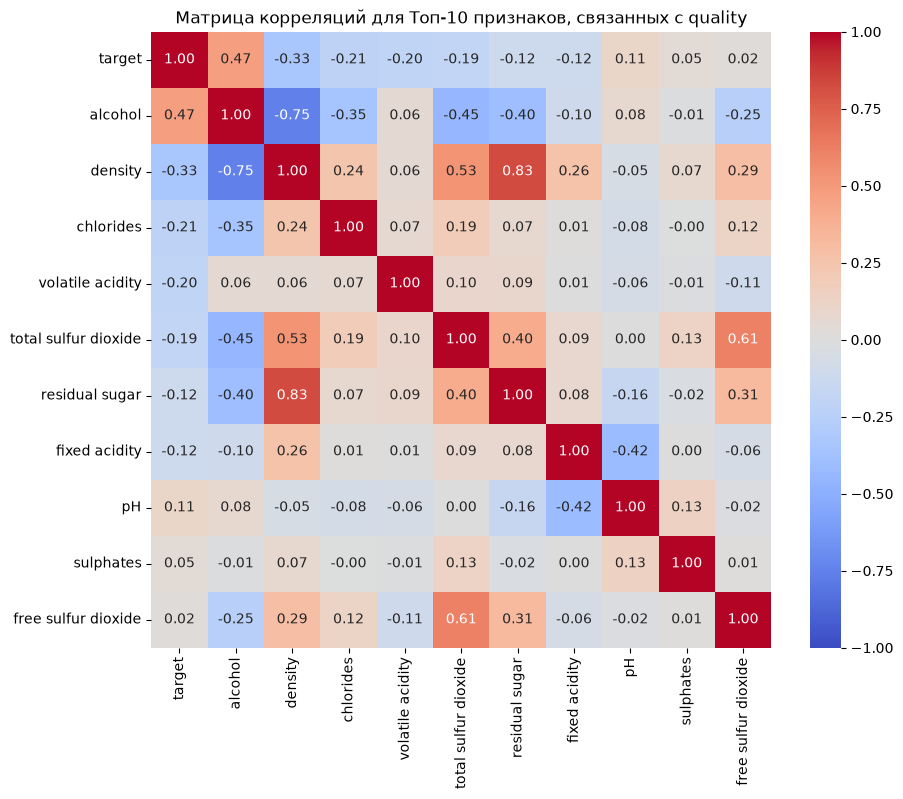

In [50]:
df = wine.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", df.shape)
X, y = df.drop(columns="quality"), df["quality"].astype("float32")
Xtr_df, Xva_df, Xte_df, ytr, yva, yte = split_dataset(X, y, stratify=False)
Xtr, Xva, Xte, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)

train_df = Xtr_df.copy()
train_df['target'] = ytr
full_corr = train_df.corr(method='pearson', numeric_only=True)

top_features = full_corr['target'].abs().sort_values(ascending=False).head(11).index

plt.figure(figsize=(10, 8))
sns.heatmap(full_corr.loc[top_features, top_features], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций для Топ-10 признаков, связанных с quality")
plt.show()

**Утечка и дубликаты.** Идентификаторов и признаков, раскрывающих `quality`, в наборе нет — все 11 признаков физико-химические.
В белом вине много полных дубликатов строк; при случайном разбиении одна и та же строка могла бы попасть и в train, и в test, что завышает
метрики. Поэтому дубликаты удаляются **до разбиения** (`DROP_DUPLICATES = True`). Пропусков нет; импутация всё равно включена в конвейер.
Целевой признак не масштабируется (шкала 3–9), поэтому MSE/MAE сразу в исходных единицах.

In [52]:
def reg_metrics(y, p):
    return dict(MSE=mean_squared_error(y, p), MAE=mean_absolute_error(y, p), R2=r2_score(y, p))

reg_rows, reg_hist, reg_models = [], {}, {}

for cfg0 in CFGS:
    cfg = cfg0 

    model = build_mlp(cfg, Xtr.shape[1], "regression")

    es = callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva),
                  epochs=200, batch_size=cfg["batch"],
                  callbacks=[es], verbose=0)

    reg_hist[cfg["name"]], reg_models[cfg["name"]] = h.history, model
    P = {k: model.predict(v, verbose=0).ravel() for k, v in dict(tr=Xtr, va=Xva, te=Xte).items()}
    reg_rows.append(dict(Модель=cfg["name"], Эпох=int(np.argmin(h.history["val_loss"]))+1,
        **{"Train MSE": reg_metrics(ytr, P["tr"])["MSE"], "Val MSE": reg_metrics(yva, P["va"])["MSE"], "Val R2": reg_metrics(yva, P["va"])["R2"]},
        **{f"Test {k}": v for k, v in reg_metrics(yte, P["te"]).items()}))
    print(f"{cfg['name']}: лучшая эпоха {reg_rows[-1]['Эпох']}, val MSE={reg_rows[-1]['Val MSE']:.4f}")

reg_df = pd.DataFrame(reg_rows)
reg_df["Переобучение (Val MSE − Train MSE)"] = reg_df["Val MSE"] - reg_df["Train MSE"]


MLP-1: лучшая эпоха 197, val MSE=0.5431
MLP-2: лучшая эпоха 60, val MSE=0.5242
MLP-3: лучшая эпоха 18, val MSE=0.5623
MLP-4: лучшая эпоха 27, val MSE=0.5399
MLP-5: лучшая эпоха 10, val MSE=0.5290


Модель  Эпох  Train MSE  Val MSE  Val R2  Test MSE  Test MAE  Test R2  Переобучение (Val MSE − Train MSE)
 MLP-1    84     0.4378   0.5476  0.3047    0.5343    0.5781   0.3194                              0.1098
 MLP-2    99     0.4458   0.5118  0.3502    0.5251    0.5666   0.3311                              0.0660
 MLP-3    91     0.3966   0.5170  0.3436    0.5337    0.5777   0.3202                              0.1205
 MLP-4    39     0.4450   0.5337  0.3224    0.5476    0.5744   0.3025                              0.0887
 MLP-5     8     0.4367   0.5342  0.3218    0.5413    0.5690   0.3105                              0.0975


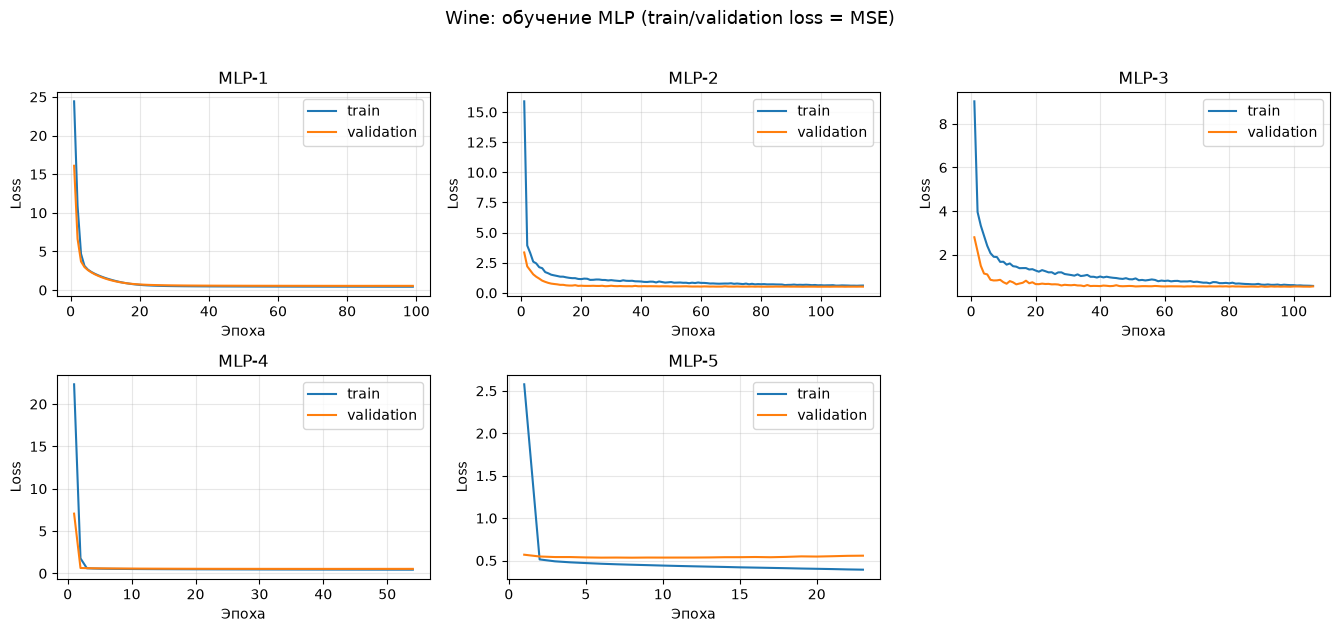

In [ ]:
display_cols = ["Модель", "Эпох", "Train MSE", "Val MSE", "Val R2", "Test MSE", "Test MAE", "Test R2", "Переобучение (Val MSE − Train MSE)"]
print(reg_df[display_cols].round(4).to_string(index=False))
plot_histories(reg_hist, "Wine: обучение MLP (train/validation loss = MSE)")

Лучшая модель по Val MSE: MLP-2


Text(0.5, 0, 'y − ŷ')

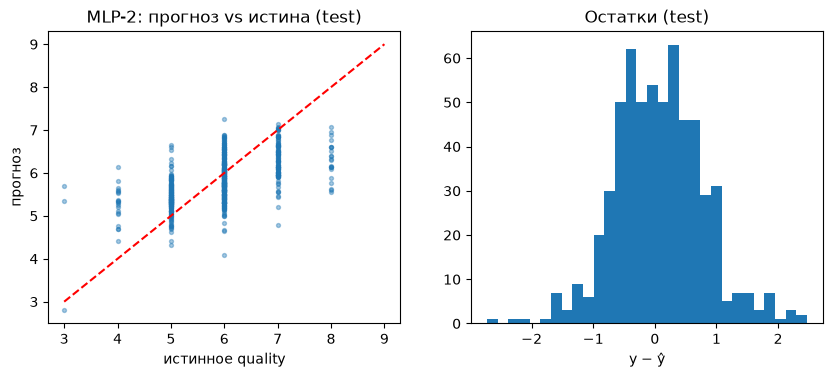

In [ ]:
nn = reg_df[reg_df["Модель"].str.startswith("MLP")]
best_name = nn.loc[nn["Val MSE"].idxmin(), "Модель"]

print("Лучшая модель по Val MSE:", best_name)
best = reg_models[best_name]; pte = best.predict(Xte, verbose=0).ravel()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(yte, pte + np.random.default_rng(SEED).normal(0, .04, len(pte)), s=8, alpha=.4)
ax[0].plot([3, 9], [3, 9], "r--"); ax[0].set_xlabel("истинное quality"); ax[0].set_ylabel("прогноз"); ax[0].set_title(f"{best_name}: прогноз vs истина (test)")
ax[1].hist(yte - pte, bins=30); ax[1].set_title("Остатки (test)"); ax[1].set_xlabel("y − ŷ")

## 4. Выводы

### Бинарная классификация (Diabetes)
  Выборка: 253 680 объектов, положительный класс (преддиабет/диабет) 15,76 %, доли сохранены стратификацией
  в train/val/test (70/15/15). Для компенсации дисбаланса использован class_weight (только на train),
  порог выбирался по validation (максимум Balanced Accuracy), итоговый порог 0,50–0,55.
  Базовая модель (Dummy, prior) предсказывает только класс 0: Recall = Precision = 0, Balanced Accuracy = 0,5, ROC-AUC = 0,5.
  Все пять MLP заметно лучше базовой. Лучшая по Val ROC-AUC — MLP-3 (128-64-32, ReLU, Adam, Dropout 0,3, L2 1e-4):
  на test Recall = 0,781, Precision = 0,338, Balanced Accuracy = 0,747, ROC-AUC = 0,824.
  Ориентир 0,80 достигнут только по ROC-AUC; Recall (0,76–0,80) близок к ориентиру, Precision (~0,33) и
  Balanced Accuracy (~0,75) ниже. Причина: признаки — анкетные ответы, диабет по ним разделяется неполно,
  а положительный класс редкий, поэтому при высокой полноте падает точность (компромисс Recall/Precision).
  Архитектуры различаются слабо (Val ROC-AUC 0,822–0,825, разница сопоставима с шумом): усложнение сети
  качество не повышает. Лучшие эпохи приходятся на 3–26, то есть Early Stopping срабатывает рано.

### Многоклассовая классификация (Body Performance)
  Классы A–D сбалансированы (по 25 %), 13 393 объекта. Базовая модель: Balanced Accuracy = 0,25, macro ROC-AUC = 0,5.
  По Val Balanced Accuracy лучшая — MLP-2 (64-32, ReLU, Adam, Dropout 0,2): на test Balanced Accuracy = 0,747,
  macro ROC-AUC (OvR) = 0,926, macro F1 = 0,746. По классам (F1 / AUC): A 0,784 / 0,951; B 0,627 / 0,884;
  C 0,708 / 0,907; D 0,866 / 0,963. Класс D распознаётся лучше всего, класс B — хуже всего
  (соседние по уровню классы смешиваются, Recall B = 0,62, Recall C = 0,66).
  Macro ROC-AUC выше ориентира 0,80, Balanced Accuracy (0,75) ниже. Разница между всеми MLP около 0,01,
  то есть архитектура практически не влияет; на test Balanced Accuracy от 0,747 до 0,759.
  Выбор сделан по validation, а не по test, как требует методика.

### Регрессия (Wine Quality, white)
  После удаления 937 полных дубликатов осталось 3961 объект (разбиение ≈ 2772/594/595, seed = 42).
  Базовая модель (среднее): Test MSE = 0,786, MAE = 0,672, R² = −0,001.
  Лучшая по Val MSE — MLP-2: Test MSE = 0,526, MAE = 0,566, R² = 0,330. MSE снижен примерно на 33 % относительно базовой модели,
  ошибка в среднем около 0,57 балла. Ориентир R² ≥ 0,80 не достигнут: оценка вина — субъективная целая шкала, сосредоточенная
  в значениях 5–7, и 11 физико-химических признаков объясняют лишь часть дисперсии. Рост сложности не помогает
  (MLP-3 хуже MLP-2). Разрыв Val−Train MSE: MLP-1 0,141, MLP-4 0,103, MLP-5 0,100, а у MLP-2 и MLP-3 с Dropout/L2 — 0,062 и 0,072,
  то есть регуляризация снижает переобучение.

### Общий вывод
  Во всех трёх задачах MLP значительно лучше базовых моделей, но ориентиры 0,80 достигнуты лишь частично
  (ROC-AUC в диабете, macro ROC-AUC в Body). Дальнейшие улучшения: градиентный бустинг/Random Forest как
  более сильный бейзлайн, подбор порога под стоимость ошибок, порядковая постановка для quality.